John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

In [21]:
# load packages
install.packages("tidyverse")
library(tidyverse)
library(tidymodels)
theme_dark()
# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' is in use and will not be installed"


<theme> List of 144
 $ line                            : <ggplot2::element_line>
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ lineend      : chr "butt"
  ..@ linejoin     : chr "round"
  ..@ arrow        : logi FALSE
  ..@ arrow.fill   : chr "black"
  ..@ inherit.blank: logi TRUE
 $ rect                            : <ggplot2::element_rect>
  ..@ fill         : chr "white"
  ..@ colour       : chr "black"
  ..@ linewidth    : num 0.5
  ..@ linetype     : num 1
  ..@ linejoin     : chr "round"
  ..@ inherit.blank: logi TRUE
 $ text                            : <ggplot2::element_text>
  ..@ family       : chr ""
  ..@ face         : chr "plain"
  ..@ italic       : chr NA
  ..@ fontweight   : num NA
  ..@ fontwidth    : num NA
  ..@ colour       : chr "black"
  ..@ size         : num 11
  ..@ hjust        : num 0.5
  ..@ vjust        : num 0.5
  ..@ angle        : num 0
  ..@ lineheight   : num 0.9
  ..@ margin       : <ggplot2::margin> nu

In [22]:
test_accuracies <- list()
song_accuracies <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies <- append(test_accuracies, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies <- append(song_accuracies, list("{file}" = read_csv(file)))
    }
}

test_accuracies <- bind_rows(test_accuracies)
song_accuracies <- bind_rows(song_accuracies)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs in last 60s_song_accuracies.csv"


Rows: 201 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs in last 60s_test_accuracies.csv"


Rows: 11 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs since last own song_song_accuracies.csv"


Rows: 201 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (26 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Own Song History_song_accuracies.csv"


Rows: 206 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Own Song History_test_accuracies.csv"


Rows: 11 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [32]:
test_accuracies %>% pull(model) %>% unique()

[1] "All songs in last 60s"                                
[2] "All songs since last own song"                        
[3] "Attention 30s"                                        
[4] "Attention"                                            
[5] "Hierarchical Classifier All songs since last own song"
[6] "Last Song from Each Neighbour"                        
[7] "Most Common Songs"                                    
[8] "Own Last Songs"                                       
[9] "Own Song History"

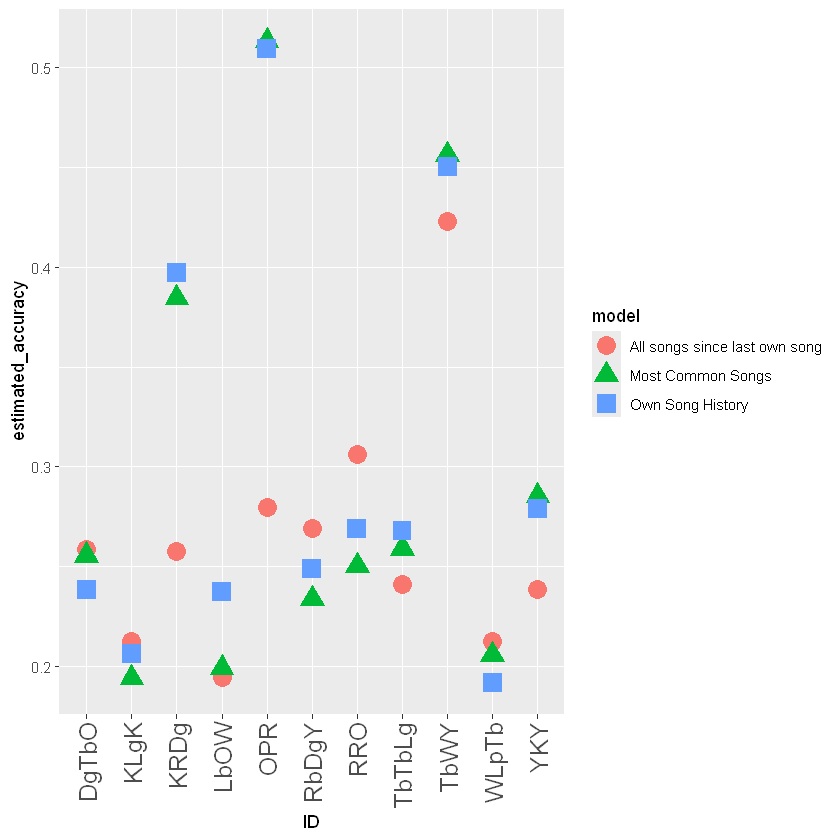

In [36]:
# TODO: Throw in baseline classifer
plot <- ggplot(data = test_accuracies %>% filter(model %in% c("Own Song History", "Most Common Songs", 'All songs since last own song')), aes(x=ID, y=estimated_accuracy, color=model, shape=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical
print(plot)

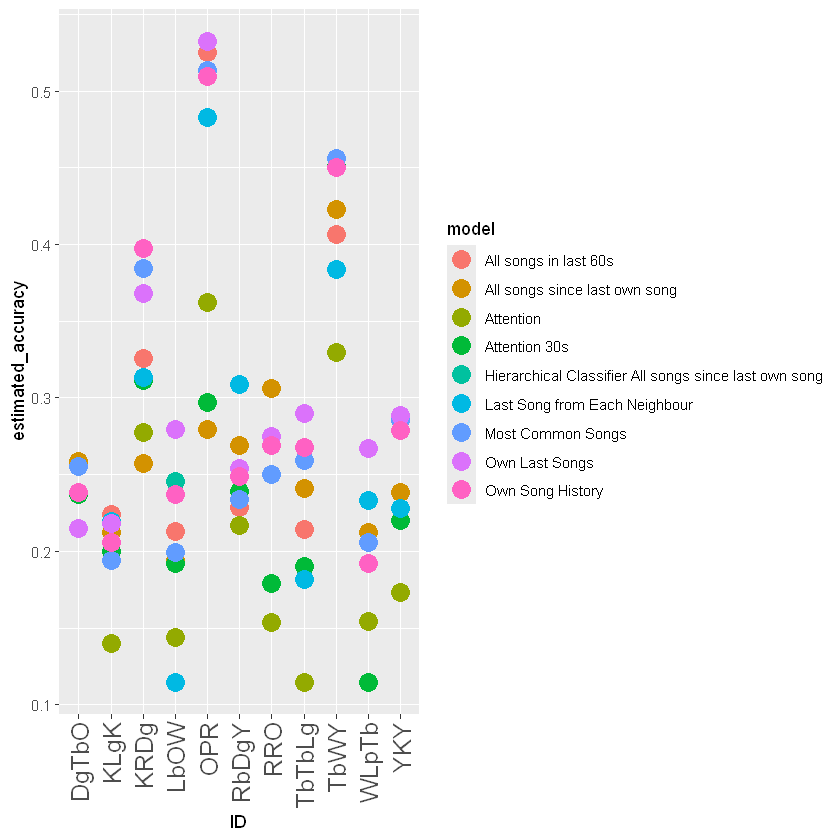

In [39]:
# TODO: Throw in baseline classifer
plot <- ggplot(data = test_accuracies, aes(x=ID, y=estimated_accuracy, color=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical
print(plot)

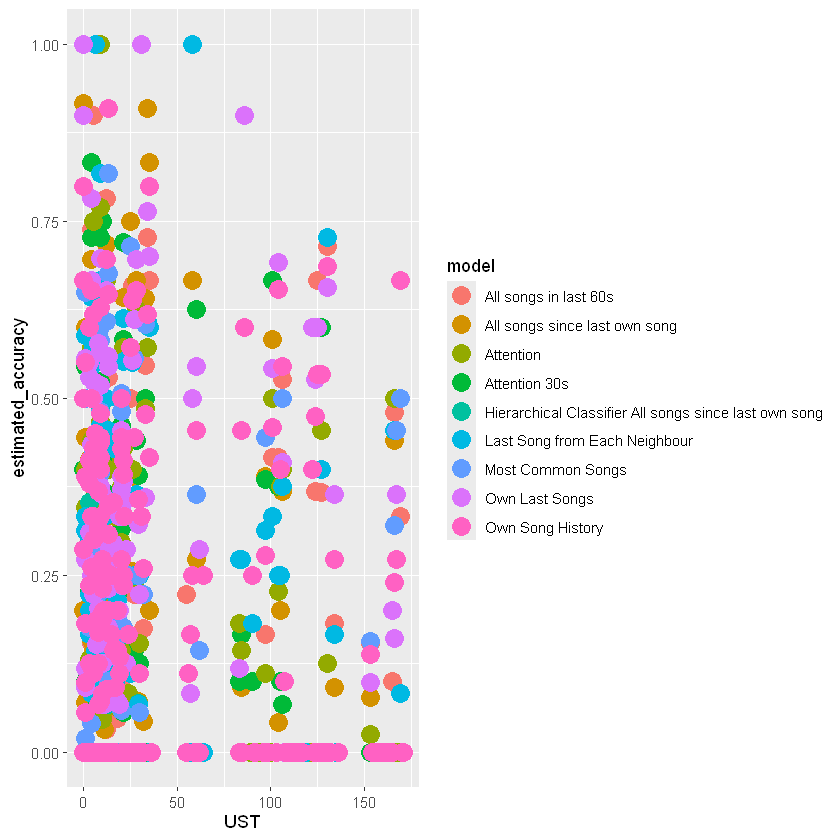

In [40]:

plot <- ggplot(data = song_accuracies, aes(x=UST, y=estimated_accuracy, color=model)) +
    geom_point(size=5)
print(plot)

Warning message:
"The shape palette can deal with a maximum of 6 discrete values because more
than 6 becomes difficult to discriminate
ℹ you have requested 9 values. Consider specifying shapes manually if you need
  that many of them."
Warning message:
"Removed 1014 rows containing missing values or values outside the scale range
(`geom_point()`)."


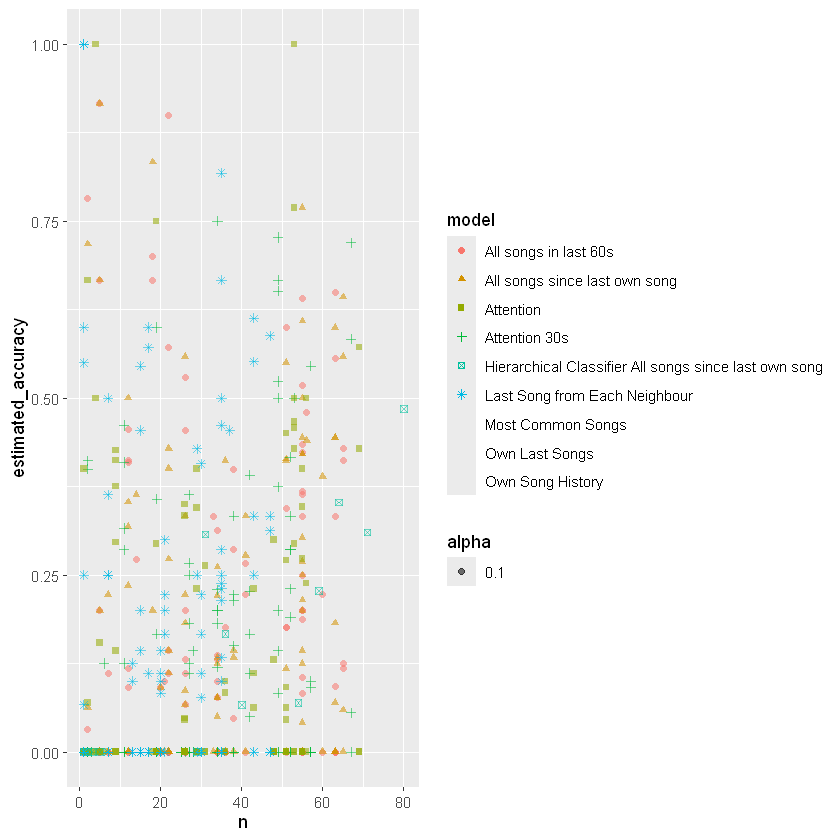

In [25]:
plot <- ggplot(data=song_accuracies) + 
    aes(x=n, y=estimated_accuracy, color=model, shape=model, alpha=0.1) +
    geom_point()
print(plot)

In [26]:
song_accuracies

ID,UST,estimated_accuracy,model,n
<chr>,<dbl>,<dbl>,<chr>,<dbl>
DgTbO,33,0.54700855,All songs in last 60s,NA
DgTbO,25,0.50000000,All songs in last 60s,NA
DgTbO,20,0.45588235,All songs in last 60s,12
DgTbO,7,0.27419355,All songs in last 60s,NA
DgTbO,32,0.17391304,All songs in last 60s,NA
DgTbO,153,0.15384615,All songs in last 60s,NA
DgTbO,10,0.13684211,All songs in last 60s,34
DgTbO,1,0.09302326,All songs in last 60s,63
DgTbO,8,0.08219178,All songs in last 60s,55


In [27]:
unique(song_accuracies$model)

[1] "All songs in last 60s"                                
[2] "All songs since last own song"                        
[3] "Attention 30s"                                        
[4] "Attention"                                            
[5] "Hierarchical Classifier All songs since last own song"
[6] "Last Song from Each Neighbour"                        
[7] "Most Common Songs"                                    
[8] "Own Last Songs"                                       
[9] "Own Song History"

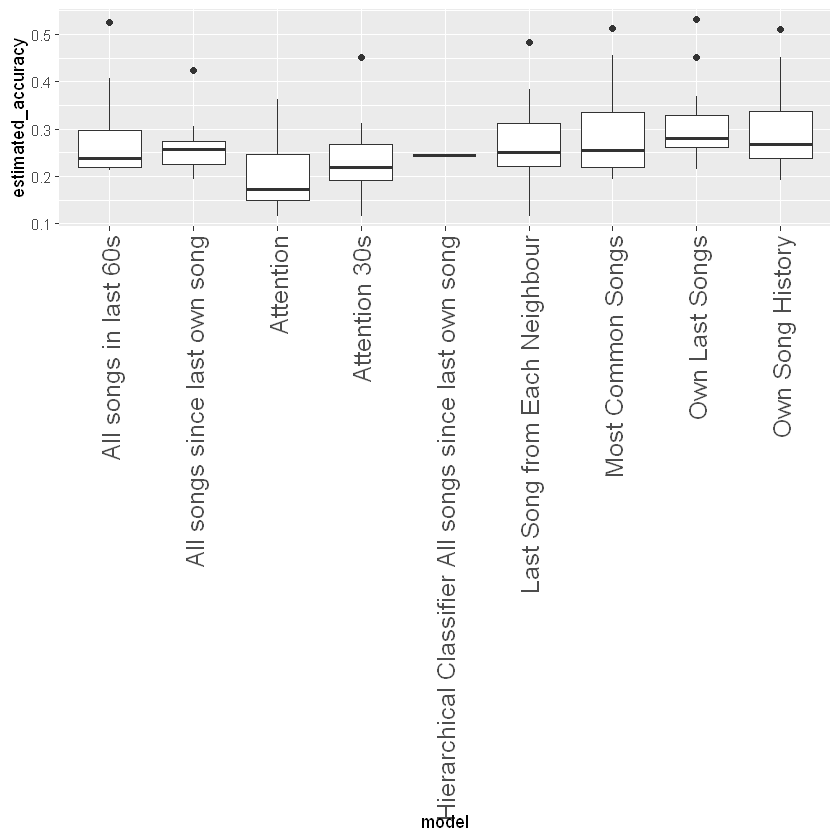

In [28]:
# Accuracy distribution of each focal male model according to models
ggplot(data=test_accuracies) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

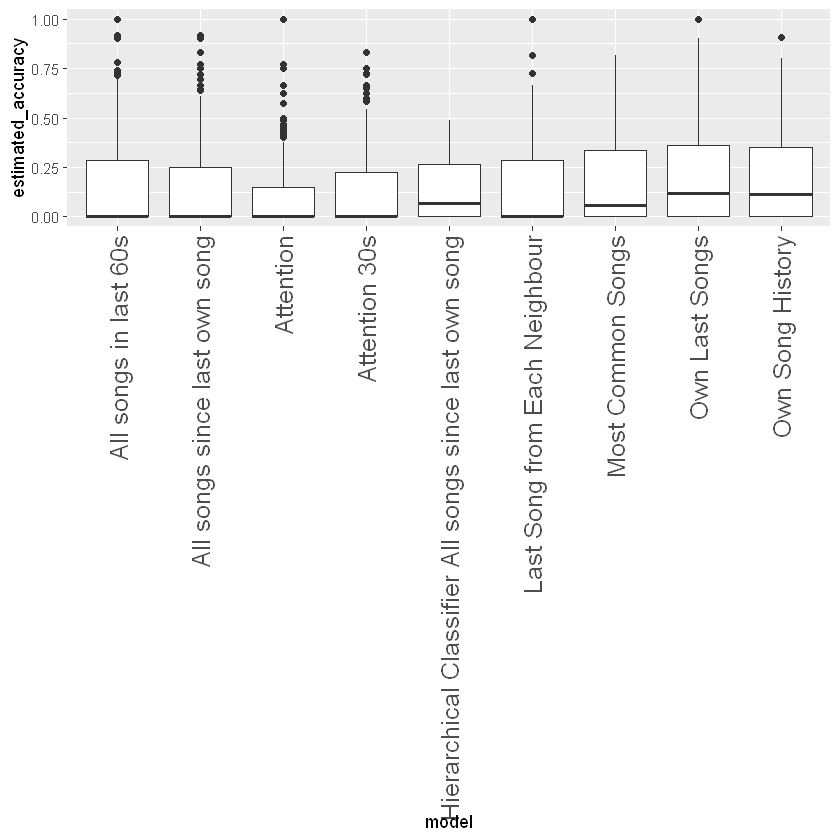

In [29]:
# Accuracy distribution of song types according to models
ggplot(data=song_accuracies) +
    aes(x=model, y=estimated_accuracy) + 
    geom_boxplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) # making x axis labels vertical

In [30]:
ggplot(data=test_accuracies) +
    geom_bar(aes(x=ID, y=estimated_accuracy))

ERROR while rich displaying an object: Error in `geom_bar()`:
! Problem while computing stat.
ℹ Error occurred in the 1st layer.
Caused by error in `setup_params()`:
! `stat_count()` must only have an x or y aesthetic.

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mim